In [2]:
import numpy as np
import matplotlib.pyplot as plt
import itertools
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize

In [3]:
def p_from_n(n,k,gam):
    result = k*((n)**gam)
    return result

def p_from_mu(k,n,mu_b,mu,gam):
    mu = k*(((n**(gam-1))+(((gam-1)/(k*gam))*(mu-mu_b)))**(gam/(gam-1)))
    return mu

def k(p_initial,n_initial,gam):
    result = p_initial/(n_initial**gam)
    return result

def mu_from_p(p,k,gam,n_intial,mu_initial):
    term1 = (((p/k)**((gam-1)/gam))-n_intial**(gam-1))*((k*gam)/gam-1)
    term2 = mu_initial
    result = term1 +term2
    return result

def n_from_p(p,k,gam):
    result = (p/k)**(1/gam)
    return result

def e_from_p(p,n,mu):
    result = (n*mu)-p
    return result

In [4]:
p_initial_had = 3.542
mu_initial_had = 977.5

n0 = 0.16
n_intial_had = 1.1*n0
gam_had = 2
k_had=k(p_initial_had,n_intial_had,gam_had)

n_pt = 6.7*n0

n_had = np.linspace(n_intial_had,n_pt,100)
p_had = p_from_n(n_had,k_had,gam_had)
mu_had = mu_from_p(p_had,k_had,gam_had,n_intial_had,mu_initial_had)

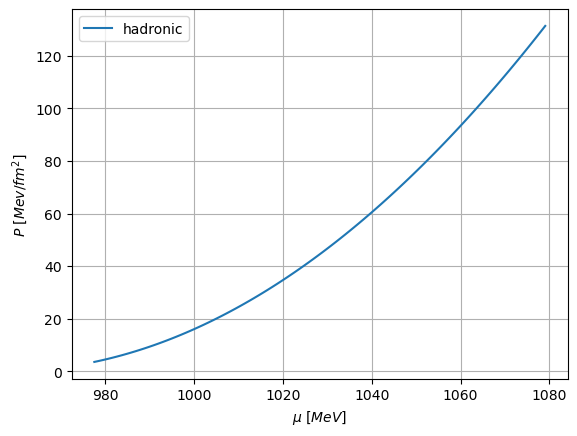

In [5]:
plt.plot(mu_had, p_had, label = "hadronic")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [6]:
gam_quark = 2
delta_n = 8*n_pt
mu_initial_quark = mu_had[-1]
n_initial_quark = n_pt + delta_n
k_quark=k(p_had[-1],n_initial_quark,gam_quark)

n_quark = np.linspace(n_initial_quark,20,100)
p_quark = p_from_n(n_quark,k_quark,gam_quark)
mu_quark = mu_from_p(p_quark,k_quark,gam_quark,n_initial_quark,mu_initial_quark)

In [7]:
n_quark

array([ 9.648     ,  9.75256566,  9.85713131,  9.96169697, 10.06626263,
       10.17082828, 10.27539394, 10.3799596 , 10.48452525, 10.58909091,
       10.69365657, 10.79822222, 10.90278788, 11.00735354, 11.11191919,
       11.21648485, 11.32105051, 11.42561616, 11.53018182, 11.63474747,
       11.73931313, 11.84387879, 11.94844444, 12.0530101 , 12.15757576,
       12.26214141, 12.36670707, 12.47127273, 12.57583838, 12.68040404,
       12.7849697 , 12.88953535, 12.99410101, 13.09866667, 13.20323232,
       13.30779798, 13.41236364, 13.51692929, 13.62149495, 13.72606061,
       13.83062626, 13.93519192, 14.03975758, 14.14432323, 14.24888889,
       14.35345455, 14.4580202 , 14.56258586, 14.66715152, 14.77171717,
       14.87628283, 14.98084848, 15.08541414, 15.1899798 , 15.29454545,
       15.39911111, 15.50367677, 15.60824242, 15.71280808, 15.81737374,
       15.92193939, 16.02650505, 16.13107071, 16.23563636, 16.34020202,
       16.44476768, 16.54933333, 16.65389899, 16.75846465, 16.86

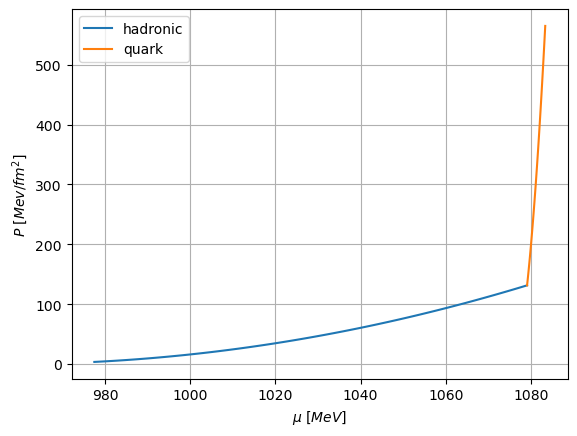

In [8]:
plt.plot(mu_had, p_had, label = "hadronic")
plt.plot(mu_quark, p_quark, label = "quark")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [9]:
# Combine hadronic and quark phases
mu_total = np.concatenate((mu_had, mu_quark))
p_total = np.concatenate((p_had, p_quark))
n_total = np.concatenate((n_had,n_quark))
e_total = e_from_p(p_total, n_total, mu_total)

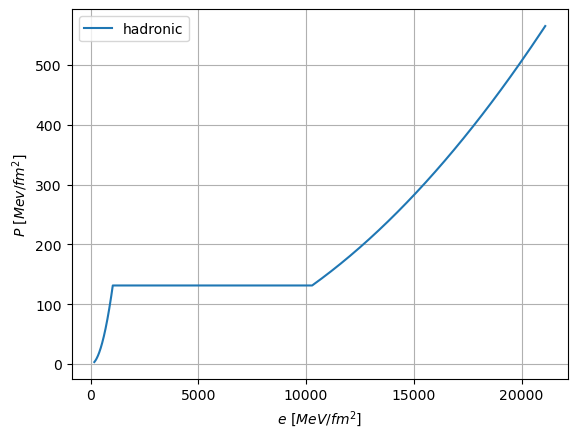

In [10]:
plt.plot(e_total, p_total, label = "hadronic")

plt.xlabel(r"$e \ [MeV/fm^2]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [11]:
def p_from_n(n,k,gam):
    result = k*((n)**gam)
    return result

def p_from_mu(k,n,mu_b,mu,gam):
    mu = k*(((n**(gam-1))+(((gam-1)/(k*gam))*(mu-mu_b)))**(gam/(gam-1)))
    return mu

def k(p_initial,n_initial,gam):
    result = p_initial/(n_initial**gam)
    return result

def mu_from_p(p,k,gam,n_intial,mu_initial):
    term1 = (((p/k)**((gam-1)/gam))-n_intial**(gam-1))*((k*gam)/gam-1)
    term2 = mu_initial
    result = term1 +term2
    return result

def n_from_p(p,k,gam):
    result = (p/k)**(1/gam)
    return result

def e_from_p(p,n,mu):
    result = (n*mu)-p
    return result

n0 = 0.16  # Nuclear saturation density
n_pt_array = np.linspace(1.1, 8, 10) * n0
gam_had_array = np.linspace(1.1, 4, 10)
gam_quark_array = np.linspace(0.5, 4, 10)

mu, p, e, n = [], [], [], []

# Combine the arrays into one loop using itertools.product
for n_pt, gam_had, gam_quark in itertools.product(n_pt_array, gam_had_array, gam_quark_array):

    # Calculate delta_n_array for the current n_pt
    delta_n_array = np.linspace(0, 9.09, 100) * n_pt

    # Iterate over delta_n_array
    for delta_n in delta_n_array:
        p_initial_had = 3.542
        mu_initial_had = 977.5

        n_initial_had = 1.1 * n0
        k_had=k(p_initial_had,n_intial_had,gam_had)

        n_had = np.linspace(n_intial_had,n_pt,100)
        p_had = p_from_n(n_had,k_had,gam_had)
        mu_had = mu_from_p(p_had,k_had,gam_had,n_intial_had,mu_initial_had)


        # Pressure and chemical potential at phase transition
        mu_initial_quark = mu_had[-1]
        n_initial_quark = n_pt + delta_n
        k_quark=k(p_had[-1],n_initial_quark,gam_quark)

        n_quark = np.linspace(n_initial_quark,20,100)
        p_quark = p_from_n(n_quark,k_quark,gam_quark)
        mu_quark = mu_from_p(p_quark,k_quark,gam_quark,n_initial_quark,mu_initial_quark)

        mu_total = np.concatenate((mu_had, mu_quark))
        p_total = np.concatenate((p_had, p_quark))
        n_total = np.concatenate((n_had,n_quark))
        e_total = e_from_p(p_total, n_total, mu_total)

        mu.append(mu_total)
        p.append(p_total)
        e.append(e_total)


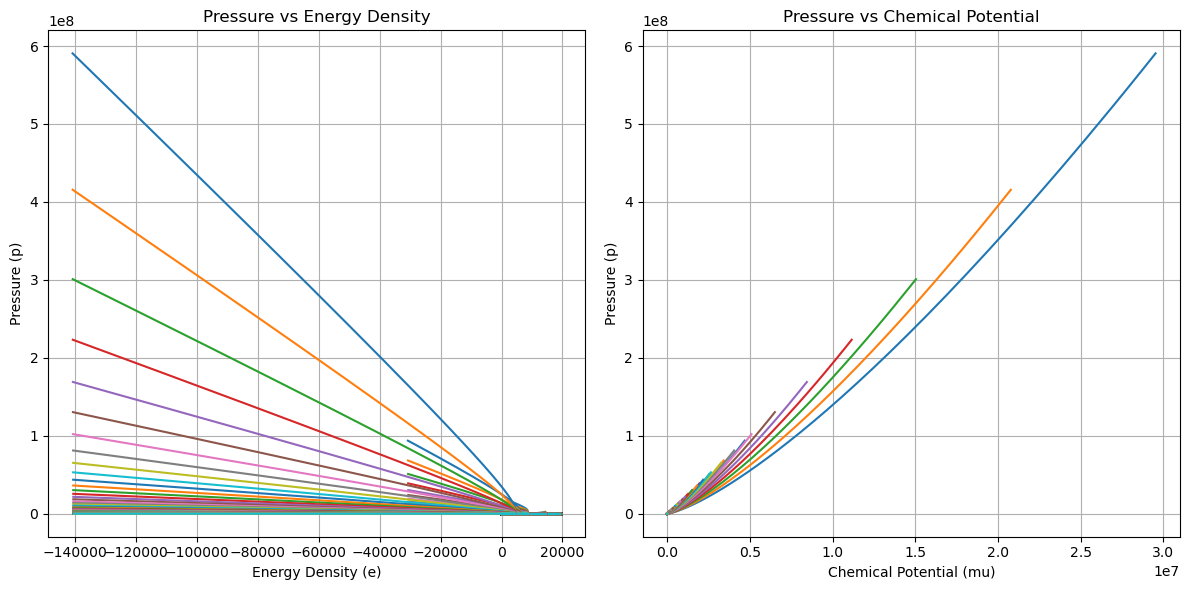

In [12]:
# Create a 2x1 grid of subplots to include both curves in one plot
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# After the loop, plot concatenated data
for i in range(1000):
    # Plot 1: Pressure vs Energy Density
    axes[0].plot(e[i], p[i], label=f"Curve {i+1}")

    # Plot 2: Pressure vs Chemical Potential
    axes[1].plot(mu[i], p[i], label=f"Curve {i+1}")

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0].set_title('Pressure vs Energy Density')
axes[0].set_xlabel('Energy Density (e)')
axes[0].set_ylabel('Pressure (p)')
axes[0].grid(True)

# Plot 2: Pressure vs Chemical Potential
axes[1].set_title('Pressure vs Chemical Potential')
axes[1].set_xlabel('Chemical Potential (mu)')
axes[1].set_ylabel('Pressure (p)')
axes[1].grid(True)

# Optionally add legends (uncomment to show)
# axes[0].legend()
# axes[1].legend()

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()
